In [1]:
import json
from pathlib import Path
import sys

sys.argv = [""]
import numpy as np
import matplotlib.pyplot as plt
import torch
import arviz as az
import ICIW_Plots
import xarray

plt.style.use("ICIWstyle")
plt.rcParams["figure.dpi"] = 600
plt.rcParams["font.size"] = 8

In [2]:
from HSA_Cam_B_035_pyro import (
    predict,
    generate_synthetic_data,
    calculate_partial_pressures,
    kl_divergence_between_models,
)
from HSA_Mo_B_011_pyro import (
    kinetics_model,
    validate_against_holdout,
    sample_prior,
    TRUE_PARAMS,
)

In [3]:
ov = [
    {
        "ID": "B_029",
        "run_name": "poky-sheep",
        "dir": Path("data/poky-sheep"),
        "DOE": "Koschany DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
    {
        "ID": "B_032",
        "run_name": "fleet-hexagon",
        "dir": Path("data/fleet-hexagon"),
        "DOE": "paramEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
    {
        "ID": "B_035",
        "run_name": "convinced-command",
        "dir": Path("data/convinced-command"),
        "DOE": "predEKLD DOE",
        "noise": "heteroscedastic",
        "noise_level": 0.1,
        "holdout_data": Path("data/test_HSA_Da_B_001.nc"),
        "idatas": None,
        "proposals": None,
        "r_obs": None,
        "valdatas": None,
        "RMSEs": None,
    },
]

In [4]:
def load_files(ov_dict):
    sum_file = ov_dict["dir"] / f"experiment_summary_{ov_dict['run_name']}.json"
    trace_files = sorted(ov_dict["dir"].glob(f"trace_*.nc"))
    test_data = xarray.open_dataset(ov_dict["holdout_data"])
    idatas = []
    valdatas = []
    for i, trace_file in enumerate(trace_files):
        idata = az.from_netcdf(trace_file)
        if i == 0:
            idata.add_groups({"prior": sample_prior(4000).prior})
        else:
            idata.add_groups({"prior": idatas[i - 1].posterior})
        idatas.append(idata)
        valdata = validate_against_holdout(
            idata,
            test_data,
            num_samples=1000,
        )
        valdatas.append(valdata)
    ov_dict["idatas"] = idatas
    ov_dict["valdatas"] = valdatas
    with open(sum_file, "r") as f:
        exp_summary = json.load(f)
    ov_dict["proposals"] = np.array(exp_summary["trials"][-1]["observed"]["x"])
    ov_dict["r_obs"] = np.array(exp_summary["trials"][-1]["observed"]["y"])

In [5]:
for ov_dict in ov:
    load_files(ov_dict)
    print(ov_dict["r_obs"])

torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



torch.Size([1000, 1]) torch.Size([1000, 5]) None


...

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



torch.Size([1000, 1]) torch.Size([1000, 5]) None


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



torch.Size([1000, 1]) torch.Size([1000, 5]) None
[[2.09568668e-07]
 [2.81178451e-04]
 [1.68815037e-04]
 [1.46153878e-04]
 [2.43372167e-04]
 [3.73580576e-07]
 [5.77398282e-07]
 [1.78115442e-05]
 [1.49500629e-04]
 [1.07190252e-04]
 [1.48787833e-04]
 [1.83522531e-07]
 [8.65557959e-05]
 [1.25837847e-04]
 [3.09257048e-05]
 [4.24680792e-07]
 [2.22270810e-05]
 [2.98106102e-07]
 [1.60867698e-04]
 [7.31930754e-07]
 [2.19703215e-04]
 [7.44794534e-07]
 [2.87172213e-07]
 [2.85910821e-04]
 [2.08815283e-04]
 [1.70939893e-04]
 [9.88544116e-07]
 [1.83236931e-04]
 [1.24680994e-07]
 [2.45795818e-04]
 [2.29704092e-04]
 [7.61396336e-07]]


c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\arviz\data\inference_data.py:1585: UserWarning:

the default dims 'chain' and 'draw' will be added automatically



In [6]:
def bRMSE(postdata, var_name):
    true = postdata.observed_data[var_name].values
    pred = postdata.posterior_predictive[var_name].values
    res = true - pred
    rmse_vals = np.sqrt(np.mean(res**2, axis=2)).squeeze()
    return rmse_vals


def calculate_RMSEs(ov_dict):
    ov_dict["RMSEs"] = None
    for valdata in ov_dict["valdatas"]:
        rmse_da = bRMSE(valdata, "r_pred")
        if ov_dict["RMSEs"] is None:
            ov_dict["RMSEs"] = [rmse_da]
        else:
            ov_dict["RMSEs"].append(rmse_da)
    ov_dict["RMSEs"] = np.array(ov_dict["RMSEs"])

In [7]:
for ov_dict in ov:
    calculate_RMSEs(ov_dict)

C:\Users\hanne\AppData\Local\Temp\ipykernel_21636\3489626561.py:33: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



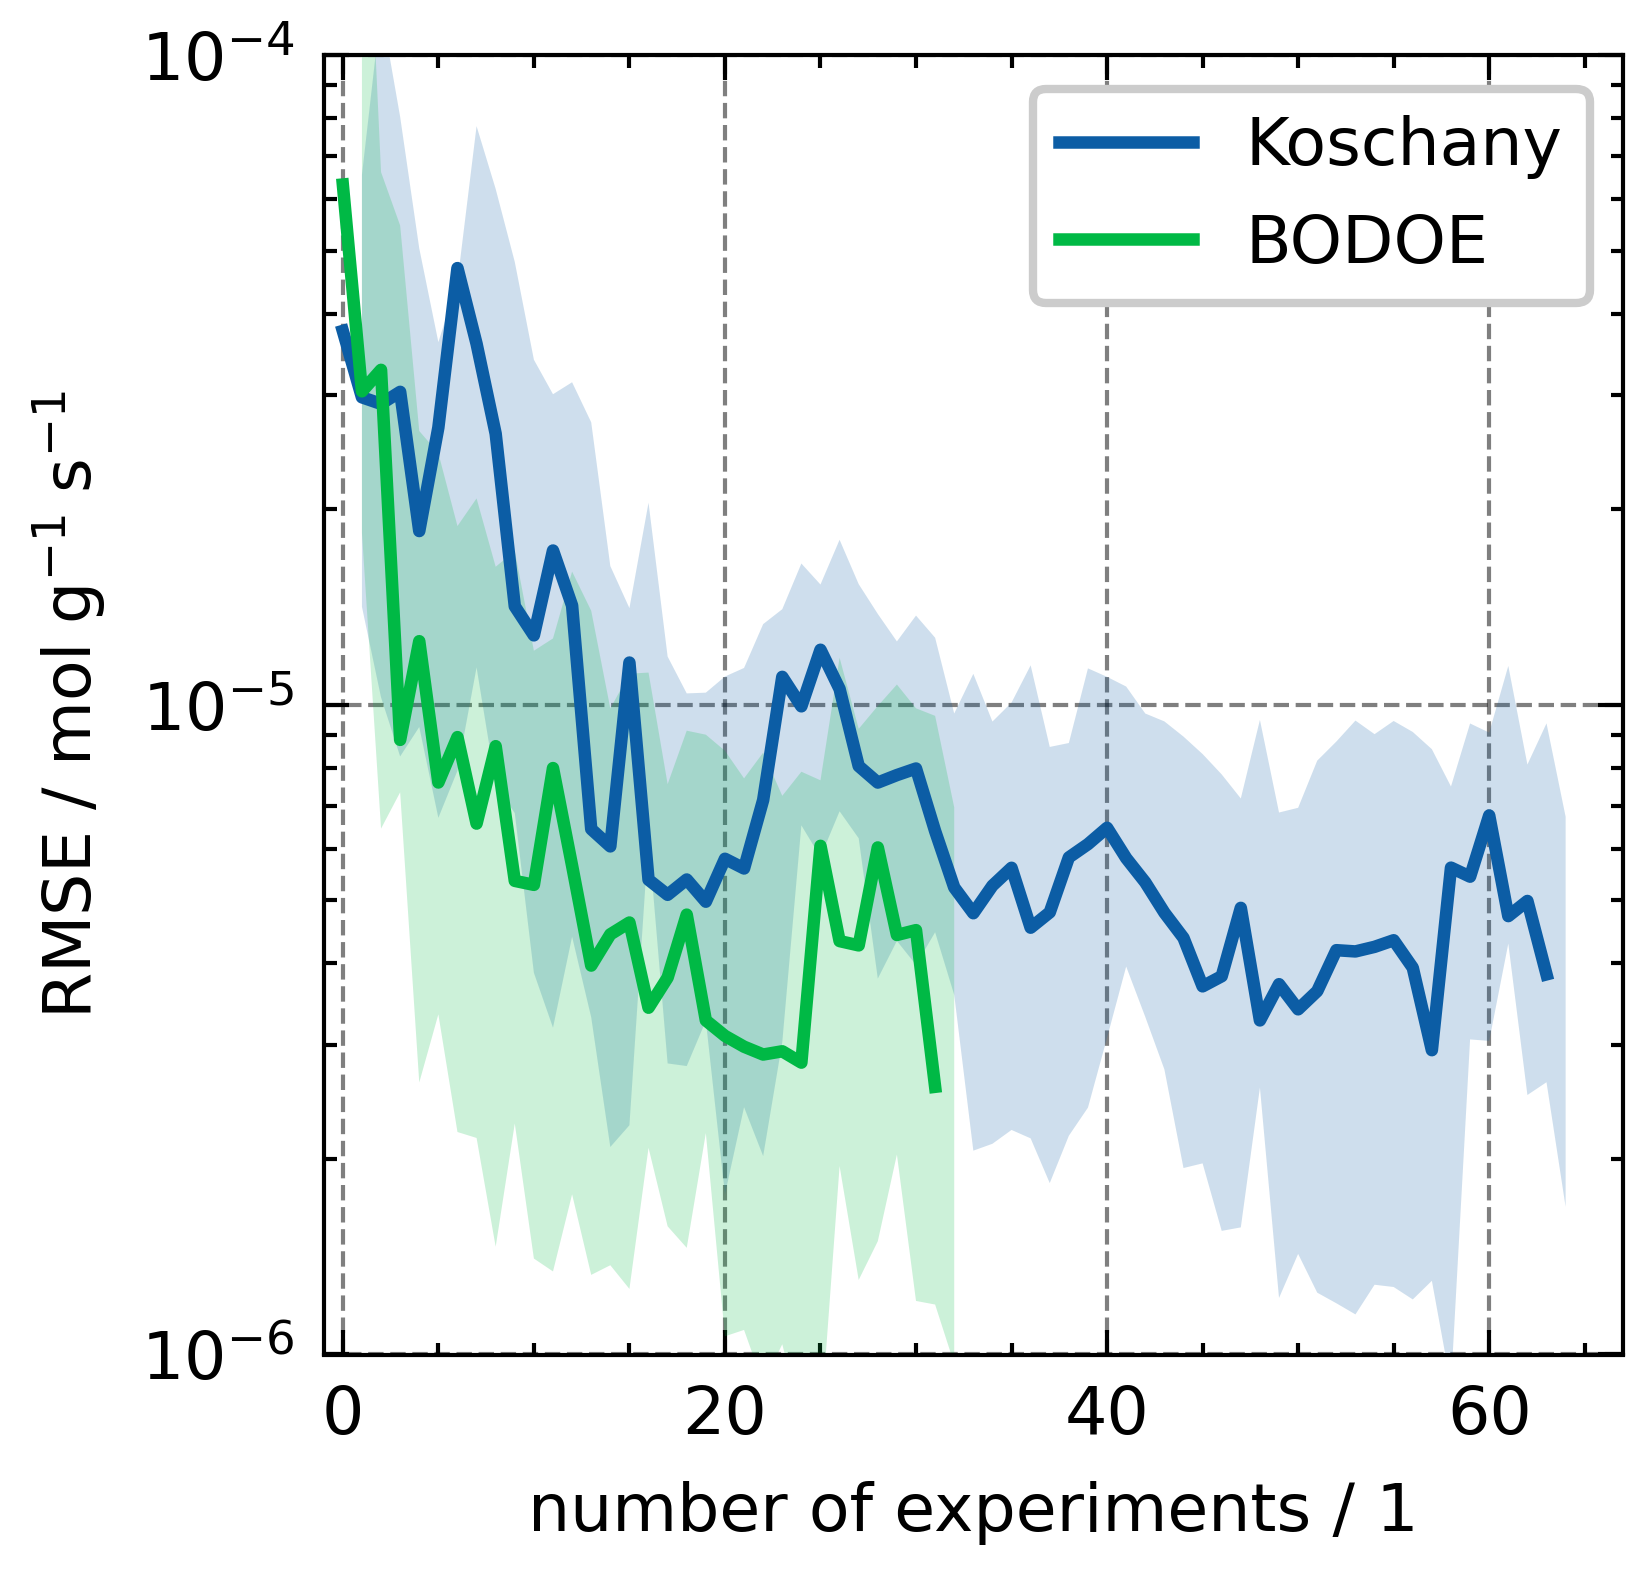

In [11]:
fig = ICIW_Plots.figure()
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="number of experiments / 1",
    ylabel=r"RMSE / $\mathrm{mol}\;\mathrm{g}^{-1}\;\mathrm{s}^{-1}$",
    yscale="log",
    ylim=(1e-6, 1e-4),
    xlim=(-1, 67),
)

for ov_dict in ov:
    if ov_dict["DOE"] == "predEKLD DOE":
        continue
    if ov_dict["DOE"] == "paramEKLD DOE":
        label = "BODOE"
    else:
        label = "Koschany"
    ax.plot(
        np.median(ov_dict["RMSEs"], axis=1),
        label=label,
    )
    ax.fill_between(
        np.arange(1, len(ov_dict["RMSEs"]) + 1),
        np.quantile(ov_dict["RMSEs"], 0.025, axis=1),
        np.quantile(ov_dict["RMSEs"], 0.975, axis=1),
        alpha=0.2,
        ls="--",
        # edgecolor="gray",
    )
    ax.legend(frameon=True)

plt.savefig("B_035_RMSE.png", dpi=600, bbox_inches="tight")

In [9]:
def evaluate_conditions(proposal, idata, key="posterior"):
    """
    Evaluate posterior predictions over temperature range at given conditions.

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions
        idata: ArviZ InferenceData with posterior samples

    Returns:
        predictions: Array of shape (100, n_samples) with rate predictions
    """
    # Extract conditions from proposal
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    c2m = torch.tensor([[proposal[3]]])
    c2w = torch.tensor([[proposal[4]]])
    c2i = torch.tensor([[proposal[5]]])
    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range for evaluation
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # Generate posterior predictions
    predictions = predict(idata, T, p_i, key=key, num_samples=1000)

    return predictions


def evaluate_true_model(proposal):
    """
    Compute true model predictions (for comparison with posterior).

    Args:
        proposal: Array [T, p, c2h, f, c2i] defining experimental conditions

    Returns:
        true_rates: Array of shape (100, 1) with true rate predictions
    """
    # Extract conditions
    p = torch.tensor([[proposal[1]]])
    c2h = torch.tensor([[proposal[2]]])
    c2m = torch.tensor([[proposal[3]]])
    c2w = torch.tensor([[proposal[4]]])
    c2i = torch.tensor([[proposal[5]]])

    # Calculate partial pressures
    p_i = calculate_partial_pressures(p, c2h, c2m, c2w, c2i)

    # Temperature range
    T = torch.linspace(500.0, 600.0, 100).reshape(-1, 1)

    # True model prediction
    _, _, true_rates = generate_synthetic_data(
        T, p, c2h, c2m, c2w, c2i, rel_noise_std=0.0
    )

    return true_rates.cpu().numpy()


def plot_predictions(fig, ax, posterior_preds, T_range):
    """
    Visualize posterior predictions vs true model with uncertainty.

    Args:
        proposal: Experimental conditions [T, p, c2h, f, c2i]
        posterior_preds: Posterior predictions (100, n_samples)
        true_preds: True model predictions (100, 1)
        T_range: Temperature values for x-axis
    """

    # Posterior mean
    ax.plot(
        T_range,
        posterior_preds.mean(axis=1),
        label="Posterior Mean",
        # color="blue",
    )

    # 95% credible interval
    ax.fill_between(
        T_range,
        np.percentile(posterior_preds, 2.5, axis=1),
        np.percentile(posterior_preds, 97.5, axis=1),
        alpha=0.3,
        # color="blue",
        label="95% HDI",
    )

    ax.legend(loc="upper left")
    return fig, ax

C:\Users\hanne\AppData\Local\Temp\ipykernel_21636\4197517328.py:81: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.

c:\Users\hanne\anaconda3\envs\pyroenv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



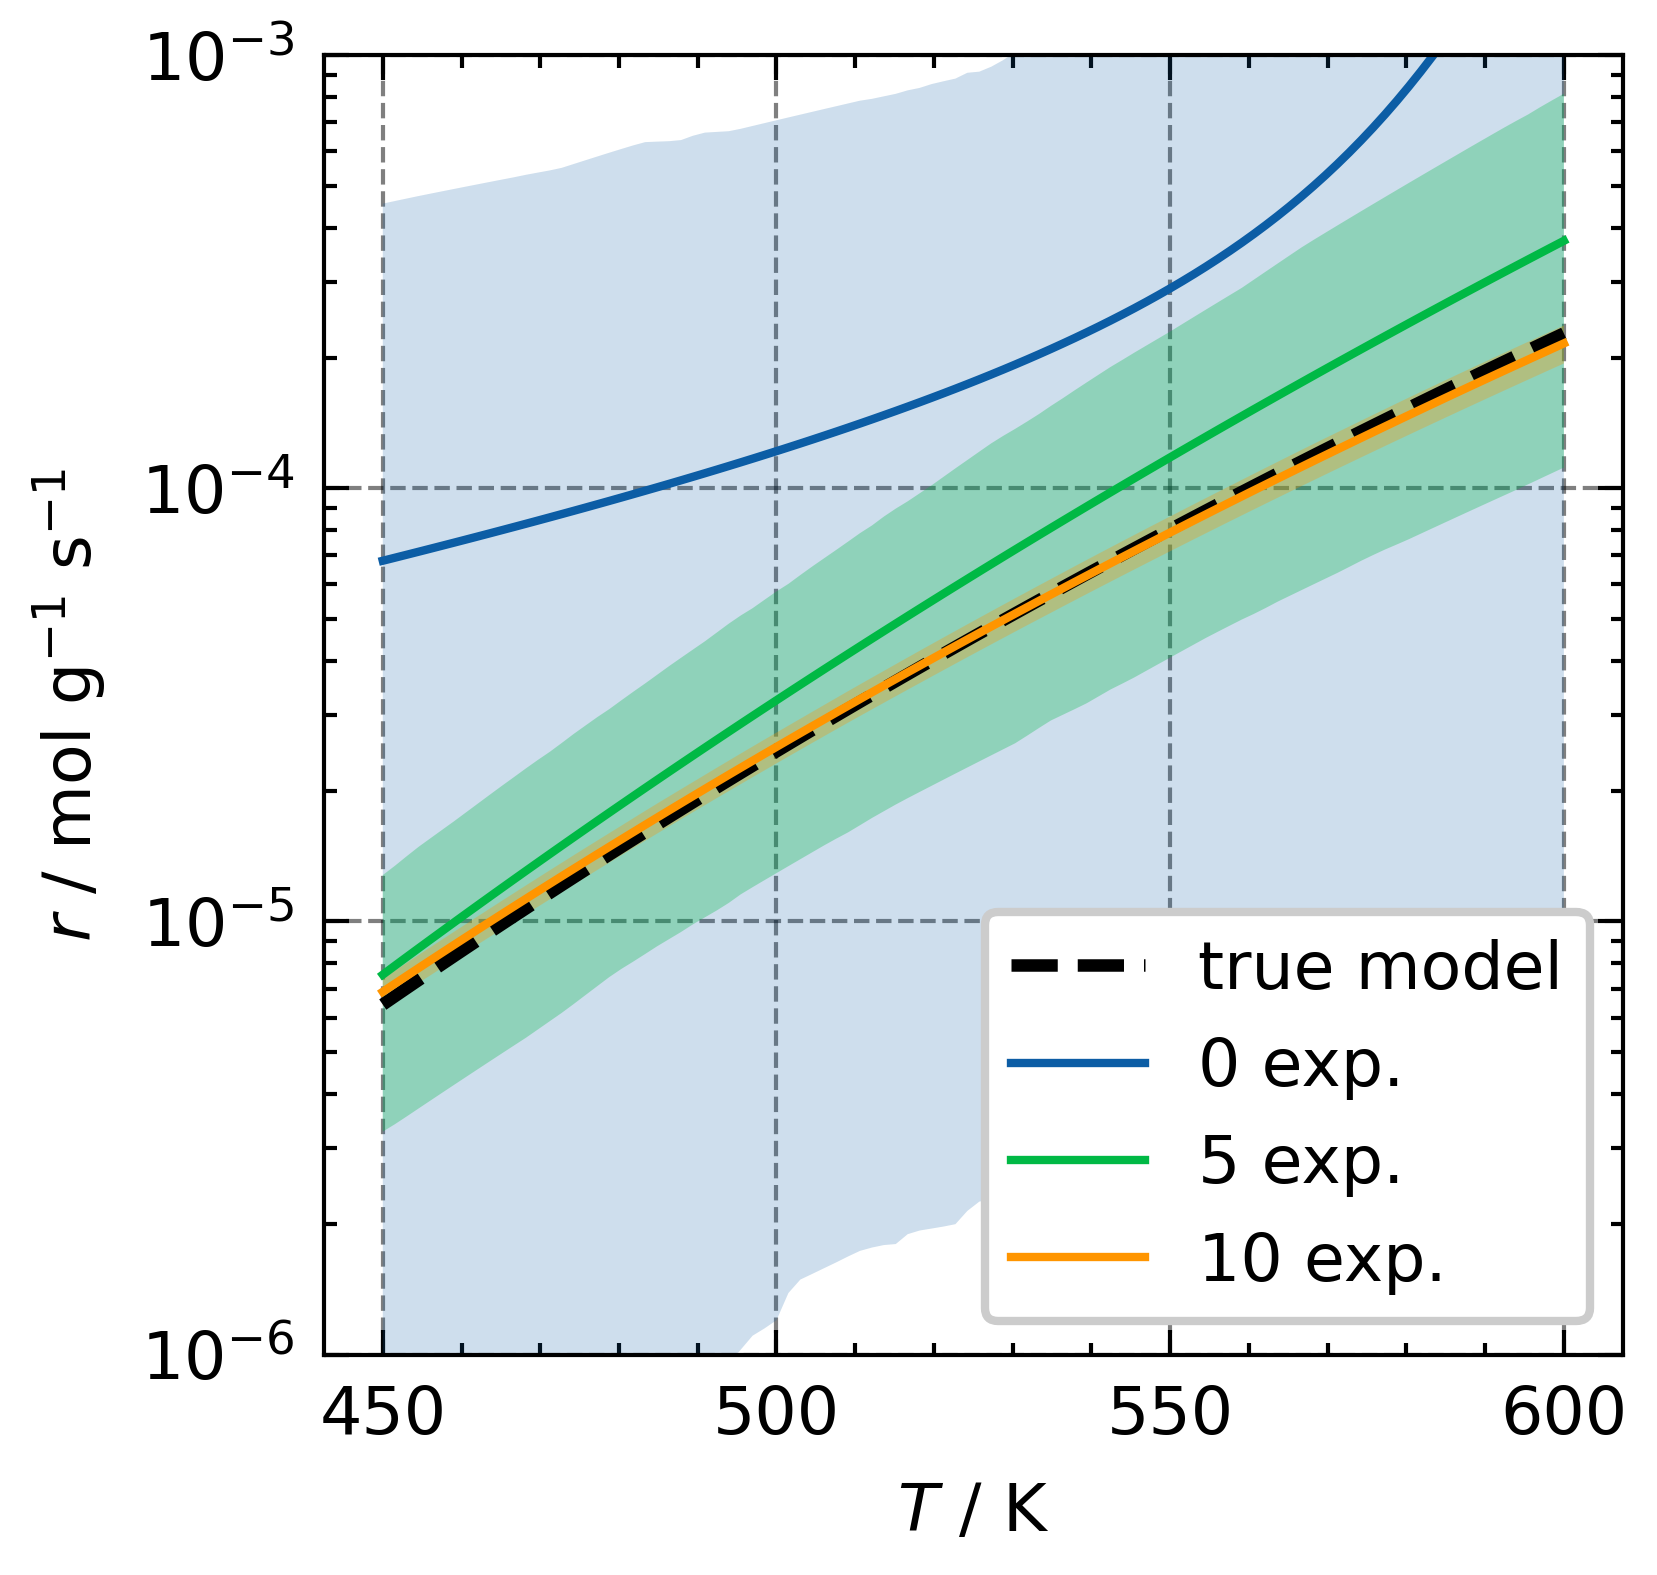

In [10]:
j = 4
T_range = np.linspace(450, 600, 100)
fig = ICIW_Plots.figure(layout="single_column")
ax = ICIW_Plots.make_square_ax(
    fig,
    ax_width=5.5 * ICIW_Plots.cm2inch,
    xlabel="$T$ / K",
    ylabel="$r$ / mol g$^{-1}$ s$^{-1}$",
    yscale="log",
    ylim=(1e-6, 1e-3),
    # xlim=(450, 600),
)
true_res = evaluate_true_model(
    proposal=ov[-1]["proposals"][j],
)
ax.plot(
    T_range,
    true_res.squeeze(),
    label="true model",
    color="black",
    linestyle="--",
    # linewidth=2,
)
# i=0
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][0],
    key="prior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="0 exp.",
    linewidth=1.0,
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.2,
)
# i=5
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][5],
    key="posterior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="5 exp.",
    linewidth=1.0,
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
)
# i=10
test_res = evaluate_conditions(
    proposal=ov[-1]["proposals"][j],
    idata=ov[-1]["idatas"][10],
    key="posterior",
)
ax.plot(
    T_range,
    test_res.mean(axis=1),
    label="10 exp.",
    linewidth=1.0,
    # color="firebrick",
)
ax.fill_between(
    T_range,
    np.percentile(test_res, 2.5, axis=1),
    np.percentile(test_res, 97.5, axis=1),
    alpha=0.3,
    # facecolor="firebrick",
)
plt.legend(loc="lower right", frameon=True)
plt.savefig("B_035_Predictions.png", dpi=600, bbox_inches="tight")